# Etapa 1 - Coleta: volume, redução com Parquet e dificuldades da fonte

Nesse notebook estão as respostas da etapa de coleta, que são o volume coletado, quanto o Parquet reduziu e quais
dificuldades a fonte impôs. Ele só lê os metadados gravados pelo `src/coleta.py` em `data/metadados` (nada é baixado
aqui), então antes é preciso rodar na raiz do projeto o `python src/coleta.py baixar`, depois o `benchmark` e o
`resumo`, como está no README.

O recorte são as três fases do programa federal de transferência de renda, Bolsa Família, Auxílio Brasil e Novo Bolsa
Família, de janeiro de 2019 a setembro de 2026. A primeira célula carrega as bibliotecas e lê as tabelas de
metadados da coleta.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
meta = raiz / "data" / "metadados"
bronze = raiz / "data" / "bronze"

# duas cores (CSV e Parquet) e tons neutros para texto, grade e fundo
cor_csv = "#2a78d6"
cor_parquet = "#eb6834"
tinta = "#0b0b0b"
tinta2 = "#52514e"
grade = "#e4e3df"
fundo = "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": fundo, "axes.facecolor": fundo, "axes.edgecolor": grade, "axes.labelcolor": tinta2,
    "xtick.color": tinta2, "ytick.color": tinta2, "text.color": tinta, "axes.grid": True,
    "grid.color": grade, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10,
    "legend.frameon": False, "text.parse_math": False,
})
pd.set_option("display.max_colwidth", 120)


def ler(nome):
    # lê uma tabela de data/metadados; os períodos e as lacunas ficam como texto (AAAAMM)
    return pd.read_csv(meta / nome, encoding="utf-8-sig", dtype={"periodo": str, "primeiro_periodo": str,
                                                                "ultimo_periodo": str, "primeiro": str,
                                                                "ultimo": str, "lacunas": str})


def numero(n, casas=0):
    # número no padrão brasileiro: 1.234,5
    texto = format(n, ",." + str(casas) + "f")
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


gb = 1e9  # GB decimal, como no relatório
resumo = ler("coleta_resumo_bases.csv")
arquivos = ler("coleta_arquivos.csv")
layouts = ler("layouts_por_periodo.csv")
periodos = ler("periodos_disponiveis.csv")
bench = ler("benchmark_formatos.csv")
nomes = dict(zip(resumo.base, resumo.nome))

## 1. Volume total coletado

Essa célula soma o que foi baixado e convertido em cada base, com o número de arquivos mensais, as linhas e o tamanho
em ZIP, em CSV descompactado e em Parquet.

In [2]:
tot = resumo[["periodos_ok", "n_linhas", "n_rejeitadas", "bytes_zip", "bytes_csv", "bytes_parquet"]].sum()
print("Arquivos baixados (base × mês):", numero(tot.periodos_ok))
print("Linhas em Parquet:", numero(tot.n_linhas), "| linhas malformadas fora do Parquet:", numero(tot.n_rejeitadas))
print("ZIP:", numero(tot.bytes_zip / gb, 1), "GB | CSV:", numero(tot.bytes_csv / gb, 1), "GB | Parquet:",
      numero(tot.bytes_parquet / gb, 1), "GB")
print("O Parquet ocupa", numero(100 * tot.bytes_parquet / tot.bytes_csv, 1), "% do CSV (redução de",
      numero(100 * (1 - tot.bytes_parquet / tot.bytes_csv), 1), "%)")

tabela = resumo[["nome", "periodos_ok", "primeiro_periodo", "ultimo_periodo", "n_linhas", "bytes_zip", "bytes_csv",
                 "bytes_parquet"]].copy()
for col in ["bytes_zip", "bytes_csv", "bytes_parquet"]:
    tabela[col] = (tabela[col] / gb).round(1)
tabela.columns = ["Base", "Meses", "Primeiro", "Último", "Linhas", "ZIP (GB)", "CSV (GB)", "Parquet (GB)"]
tabela

Arquivos baixados (base × mês): 94
Linhas em Parquet: 1.647.824.350 | linhas malformadas fora do Parquet: 0
ZIP: 29,4 GB | CSV: 183,4 GB | Parquet: 15,9 GB
O Parquet ocupa 8,7 % do CSV (redução de 91,3 %)


,Base,Meses,Primeiro,Último,Linhas,ZIP (GB),CSV (GB),Parquet (GB)
0,Bolsa Família - Pagamentos,35,201901,202111,494674172,9.1,55.6,5.0
1,Auxílio Brasil,16,202111,202302,293956157,5.2,32.8,2.8
2,Novo Bolsa Família,43,202303,202609,859194021,15.2,94.9,8.0


## 2. Quanto o Parquet reduziu

O gráfico compara o tamanho do CSV descompactado com o do Parquet em cada base. O Parquet guarda os dados por coluna
e comprimidos (zstd), por isso ocupa uma fração do CSV.

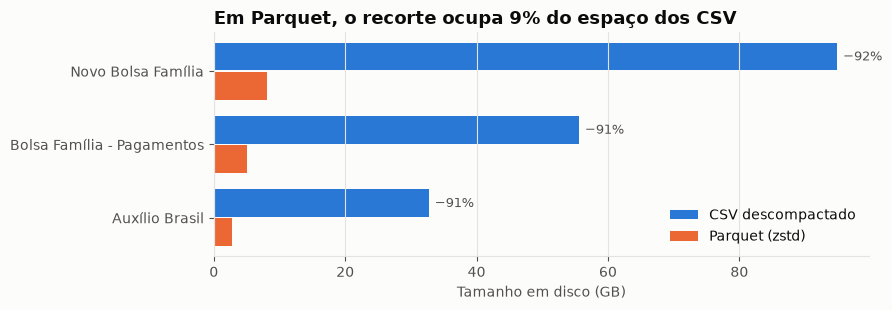

In [3]:
ok = resumo.sort_values("bytes_csv")
fig, ax = plt.subplots(figsize=(9, 3.2))
y = range(len(ok))
altura = 0.38
ax.barh([i + altura / 2 + 0.01 for i in y], ok.bytes_csv / gb, height=altura, color=cor_csv, label="CSV descompactado")
ax.barh([i - altura / 2 - 0.01 for i in y], ok.bytes_parquet / gb, height=altura, color=cor_parquet,
        label="Parquet (zstd)")
ax.set_yticks(list(y), ok.nome)
ax.set_xlabel("Tamanho em disco (GB)")
ax.grid(axis="y", visible=False)
for i in range(len(ok)):
    csv_b = ok.bytes_csv.iloc[i]
    pq_b = ok.bytes_parquet.iloc[i]
    ax.annotate("−" + numero(100 * (1 - pq_b / csv_b)) + "%", (csv_b / gb, i + altura / 2), xytext=(4, 0),
                textcoords="offset points", va="center", color=tinta2, fontsize=9)
ax.set_title("Em Parquet, o recorte ocupa " + numero(100 * ok.bytes_parquet.sum() / ok.bytes_csv.sum()) +
             "% do espaço dos CSV")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Para o tempo de leitura, cada CSV mensal dessas bases tem mais de 1 GB, e carregar o arquivo inteiro como texto com o
pandas não cabe com folga em 16 GB de memória. Por isso o `benchmark` mediu com o DuckDB a mesma consulta (contar as
linhas por UF) lendo o CSV de um mês de cada base e lendo o Parquet do mesmo mês.

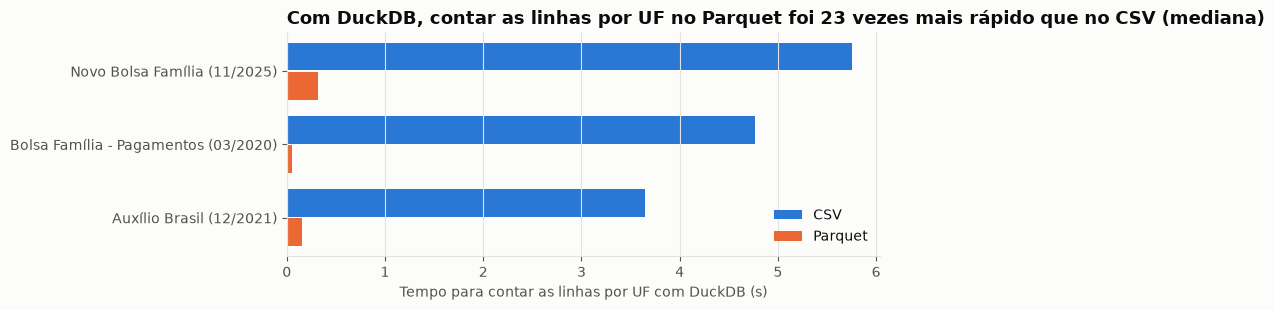

,base,periodo,n_linhas,csv_gb,parquet_gb,duckdb_csv_agrupar_s,duckdb_parquet_agrupar_s,x_mais_rapido
1,auxilio_brasil,202112,14184940,1.60,0.14,3.651,0.157,23.3
0,bolsa_familia_pagamentos,202003,13089276,1.47,0.13,4.770,0.049,97.3
2,novo_bolsa_familia,202511,18313365,2.02,0.17,5.750,0.316,18.2


In [4]:
d = bench.dropna(subset=["duckdb_csv_agrupar_s", "duckdb_parquet_agrupar_s"]).copy()
d["rotulo"] = d.base.map(nomes) + " (" + d.periodo.str[4:] + "/" + d.periodo.str[:4] + ")"
d = d.sort_values("duckdb_csv_agrupar_s")
d["x_mais_rapido"] = (d.duckdb_csv_agrupar_s / d.duckdb_parquet_agrupar_s).round(1)
vezes = d.x_mais_rapido.median()
fig, ax = plt.subplots(figsize=(9, 3.2))
y = range(len(d))
altura = 0.38
ax.barh([i + altura / 2 + 0.01 for i in y], d.duckdb_csv_agrupar_s, height=altura, color=cor_csv, label="CSV")
ax.barh([i - altura / 2 - 0.01 for i in y], d.duckdb_parquet_agrupar_s, height=altura, color=cor_parquet,
        label="Parquet")
ax.set_yticks(list(y), d.rotulo)
ax.set_xlabel("Tempo para contar as linhas por UF com DuckDB (s)")
ax.grid(axis="y", visible=False)
ax.set_title("Com DuckDB, contar as linhas por UF no Parquet foi " + numero(vezes) +
             " vezes mais rápido que no CSV (mediana)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
d["csv_gb"] = (d.bytes_csv.astype(float) / gb).round(2)
d["parquet_gb"] = (d.bytes_parquet.astype(float) / gb).round(2)
d[["base", "periodo", "n_linhas", "csv_gb", "parquet_gb", "duckdb_csv_agrupar_s", "duckdb_parquet_agrupar_s",
   "x_mais_rapido"]]

## 3. Dificuldades da fonte

### Meses publicados no Portal

Cada linha é uma base e cada trecho é o período com arquivo publicado no Portal, a partir de janeiro de 2019, que é
o início do recorte. A lista é lida da página de download de cada base pelo próprio script.

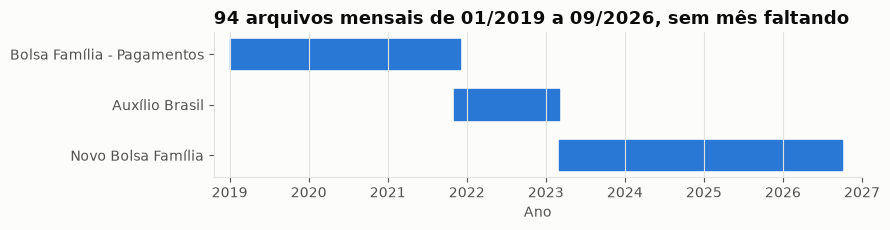

,nome,n_periodos,primeiro,ultimo,lacunas
0,Auxílio Brasil,16,202111,202302,
1,Bolsa Família - Pagamentos,35,201901,202111,
2,Novo Bolsa Família,43,202303,202609,


In [5]:
def trechos(lista):
    # meses seguidos viram um trecho (início, duração), em anos, para o gráfico
    meses = sorted(int(p[:4]) * 12 + int(p[4:6]) - 1 for p in str(lista).split(", ") if len(p.strip()) == 6)
    saida = []
    inicio = meses[0]
    anterior = meses[0]
    for m in meses[1:]:
        if m != anterior + 1:
            saida.append((inicio / 12, (anterior - inicio + 1) / 12))
            inicio = m
        anterior = m
    saida.append((inicio / 12, (anterior - inicio + 1) / 12))
    return saida


p = periodos.set_index("base").loc[["novo_bolsa_familia", "auxilio_brasil", "bolsa_familia_pagamentos"]]
fig, ax = plt.subplots(figsize=(9, 2.4))
for i in range(len(p)):
    ax.broken_barh(trechos(p.periodos.iloc[i]), (i - 0.3, 0.6), color=cor_csv)
ax.set_yticks(range(len(p)), p.nome)
ax.set_xlim(2018.8, 2027)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Ano")
total = p.n_periodos.sum()
lacunas = p.lacunas.notna().sum()  # bases com algum mês faltando
ax.set_title(str(total) + " arquivos mensais de 01/2019 a 09/2026" + (", sem mês faltando" if lacunas == 0 else ""))
plt.tight_layout()
plt.show()
periodos[["nome", "n_periodos", "primeiro", "ultimo", "lacunas"]].fillna("")

### Mudanças de layout entre períodos

Essa célula mostra quando as colunas de um arquivo mudaram em relação ao mês anterior da mesma base (nome, ordem ou
quantidade de colunas).

In [6]:
mud = layouts[layouts.versao_layout > 1]
print(len(mud), "mudança(s) de layout")
mud[["base", "versao_layout", "primeiro_periodo", "ultimo_periodo", "colunas"]]

1 mudança(s) de layout


,base,versao_layout,primeiro_periodo,ultimo_periodo,colunas
2,bolsa_familia_pagamentos,2,202111,202111,MÊS REFERÊNCIA | MÊS COMPETÊNCIA | UF | CÓDIGO MUNICÍPIO SIAFI | NOME MUNICÍPIO | CPF FAVORECIDO | NIS FAVORECIDO | ...


### Linhas malformadas, tentativas extras e codificação

Aqui estão as linhas que o leitor de CSV não conseguiu ler, as falhas de download que o script recuperou tentando de
novo e a codificação de cada arquivo.

In [7]:
okk = arquivos[arquivos.status == "ok"]
print("Linhas malformadas:", numero(okk.n_rejeitadas.sum()))
por_mes = arquivos.drop_duplicates(["base", "periodo"])
extras = (por_mes.tentativas.fillna(1) - 1).clip(lower=0).sum()
print("Tentativas extras de download (falhas recuperadas):", int(extras))
print("Downloads retomados do meio:", int(por_mes.retomado.fillna(False).astype(bool).sum()))
print("Arquivos indisponíveis ou com erro:", int((por_mes.status != "ok").sum()))
okk.groupby(["base", "encoding"]).size().rename("arquivos").reset_index()

Linhas malformadas: 0
Tentativas extras de download (falhas recuperadas): 0
Downloads retomados do meio: 0
Arquivos indisponíveis ou com erro: 0


,base,encoding,arquivos
0,auxilio_brasil,cp1252,16
1,bolsa_familia_pagamentos,cp1252,35
2,novo_bolsa_familia,cp1252,43


## 4. Conferência rápida na camada bronze

Essa célula conta as linhas gravadas em Parquet em cada base. O `count(*)` em Parquet usa só os metadados dos
arquivos, então é instantâneo mesmo com 1,6 bilhão de linhas.

In [8]:
con = duckdb.connect()
contagem = []
for base in ["bolsa_familia_pagamentos", "auxilio_brasil", "novo_bolsa_familia"]:
    padrao = (bronze / base / base / "*" / "*" / "*.parquet").as_posix()
    n = con.execute(f"SELECT count(*) FROM read_parquet('{padrao}')").fetchone()[0]
    contagem.append({"base": base, "linhas": n})
contagem = pd.DataFrame(contagem)
print("Total:", numero(contagem.linhas.sum()), "linhas")
contagem

Total: 1.647.824.350 linhas


,base,linhas
0,bolsa_familia_pagamentos,494674172
1,auxilio_brasil,293956157
2,novo_bolsa_familia,859194021


## Respostas

1\. Qual foi o volume total coletado?

Foram 94 arquivos mensais (35 do Bolsa Família, 16 do Auxílio Brasil e 43 do Novo Bolsa Família) com 1.647.824.350
linhas, de janeiro de 2019 a setembro de 2026. Baixados eles ocupam 29,4 GB em ZIP, que descompactados viram 183,4 GB
de CSV.

2\. Quanto o Parquet reduziu?

Em Parquet o recorte ficou com 15,9 GB, que é 8,7% do tamanho dos CSV (redução de 91,3%), e a redução é quase igual
nas três bases. Na leitura, contar as linhas por UF com DuckDB foi de 18 a 97 vezes mais rápido no Parquet que no CSV,
com mediana de 23 vezes.

3\. Quais dificuldades a fonte impôs?

A maior dificuldade foi o tamanho, porque cada CSV mensal tem de 1,5 a 2,4 GB e de 13 a 22 milhões de linhas, então o
script converte cada arquivo com o DuckDB sem carregar ele inteiro na memória. O servidor do Portal também recusa os
pedidos (erro 405) depois de 60 a 160 consultas seguidas, o que aconteceu na hora de consultar o tamanho dos arquivos,
então o script espera e tenta de novo. Fora isso, a única mudança de layout foi no arquivo de novembro de 2021 do
Bolsa Família, que veio com as colunas de mês trocadas, e a coleta terminou sem mês faltando e sem linha malformada.